## Interpreting the Learning Curves
We train a model by choosing weights or parameters that minimize the loss on a training set.
When we train a model we've been plotting the loss on the training set epoch by epoch. To this we'll add a plot the validation data too. These plots we call the learning curves. To train deep learning models effectively, we need to be able to interpret them.
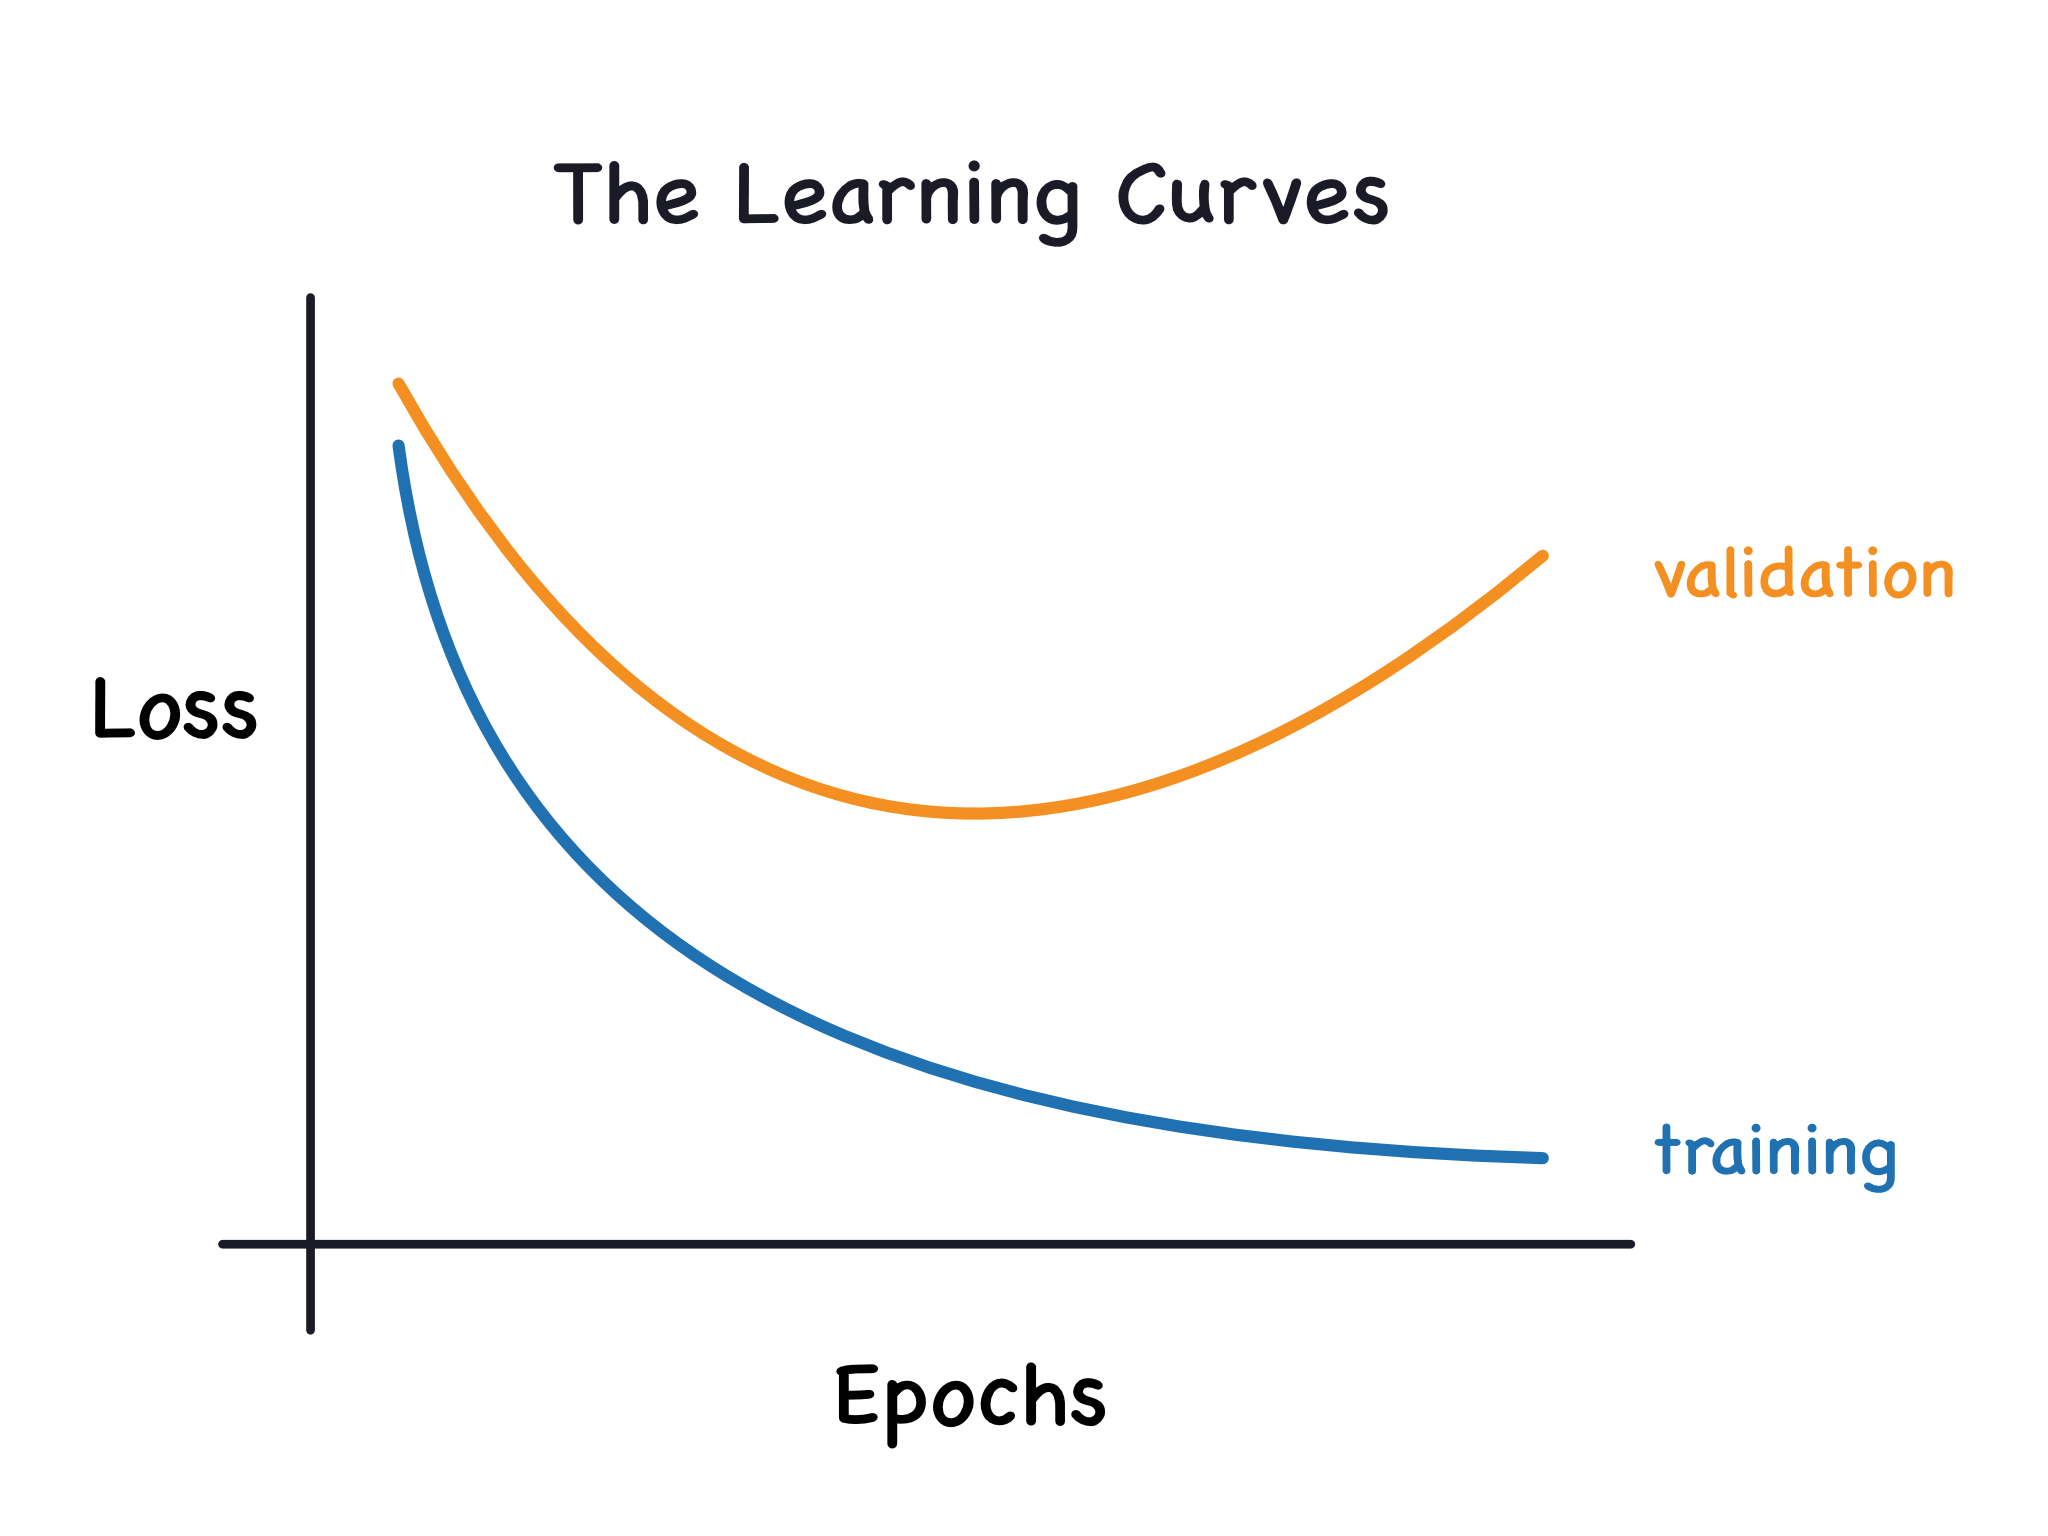

Now, the training loss will go down either when the model learns signal or when it learns noise. But the validation loss will go down only when the model learns signal. (Whatever noise the model learned from the training set won't generalize to new data.) So, when a model learns signal both curves go down, but when it learns noise a gap is created in the curves. The size of the gap tells you how much noise the model has learned.

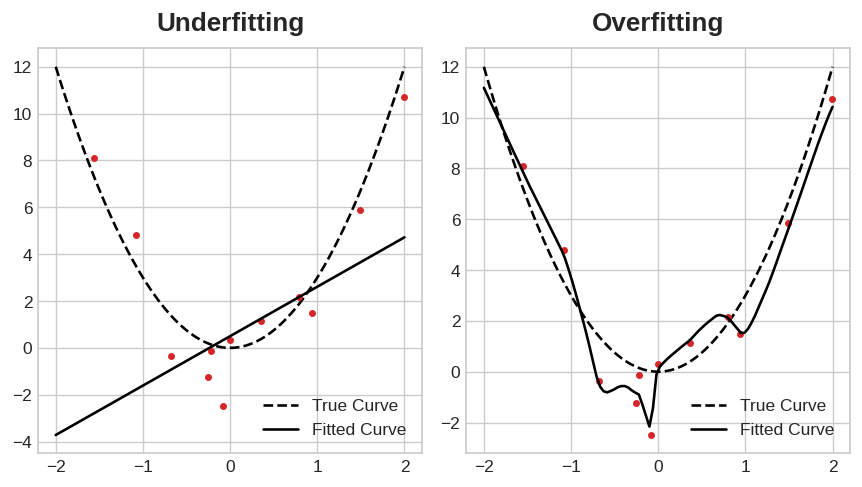
This trade-off indicates that there can be two problems that occur when training a model: not enough signal or too much noise. Underfitting the training set is when the loss is not as low as it could be because the model hasn't learned enough signal. Overfitting the training set is when the loss is not as low as it could be because the model learned too much noise. The trick to training deep learning models is finding the best balance between the two.

## Capacity
A model's capacity refers to the size and complexity of the patterns it is able to learn. For neural networks, this will largely be determined by how many neurons it has and how they are connected together. If it appears that your network is underfitting the data, we should try increasing its capacity.

we can increase the capacity of a network either by making it wider (more units to existing layers) or by making it deeper (adding more layers). Wider networks have an easier time learning more linear relationships, while deeper networks prefer more nonlinear ones. Which is better just depends on the dataset.

## Early Stopping
We mentioned that when a model is too eagerly learning noise, the validation loss may start to increase during training. To prevent this, we can simply stop the training whenever it seems the validation loss isn't decreasing anymore. Interrupting the training this way is called early stopping.

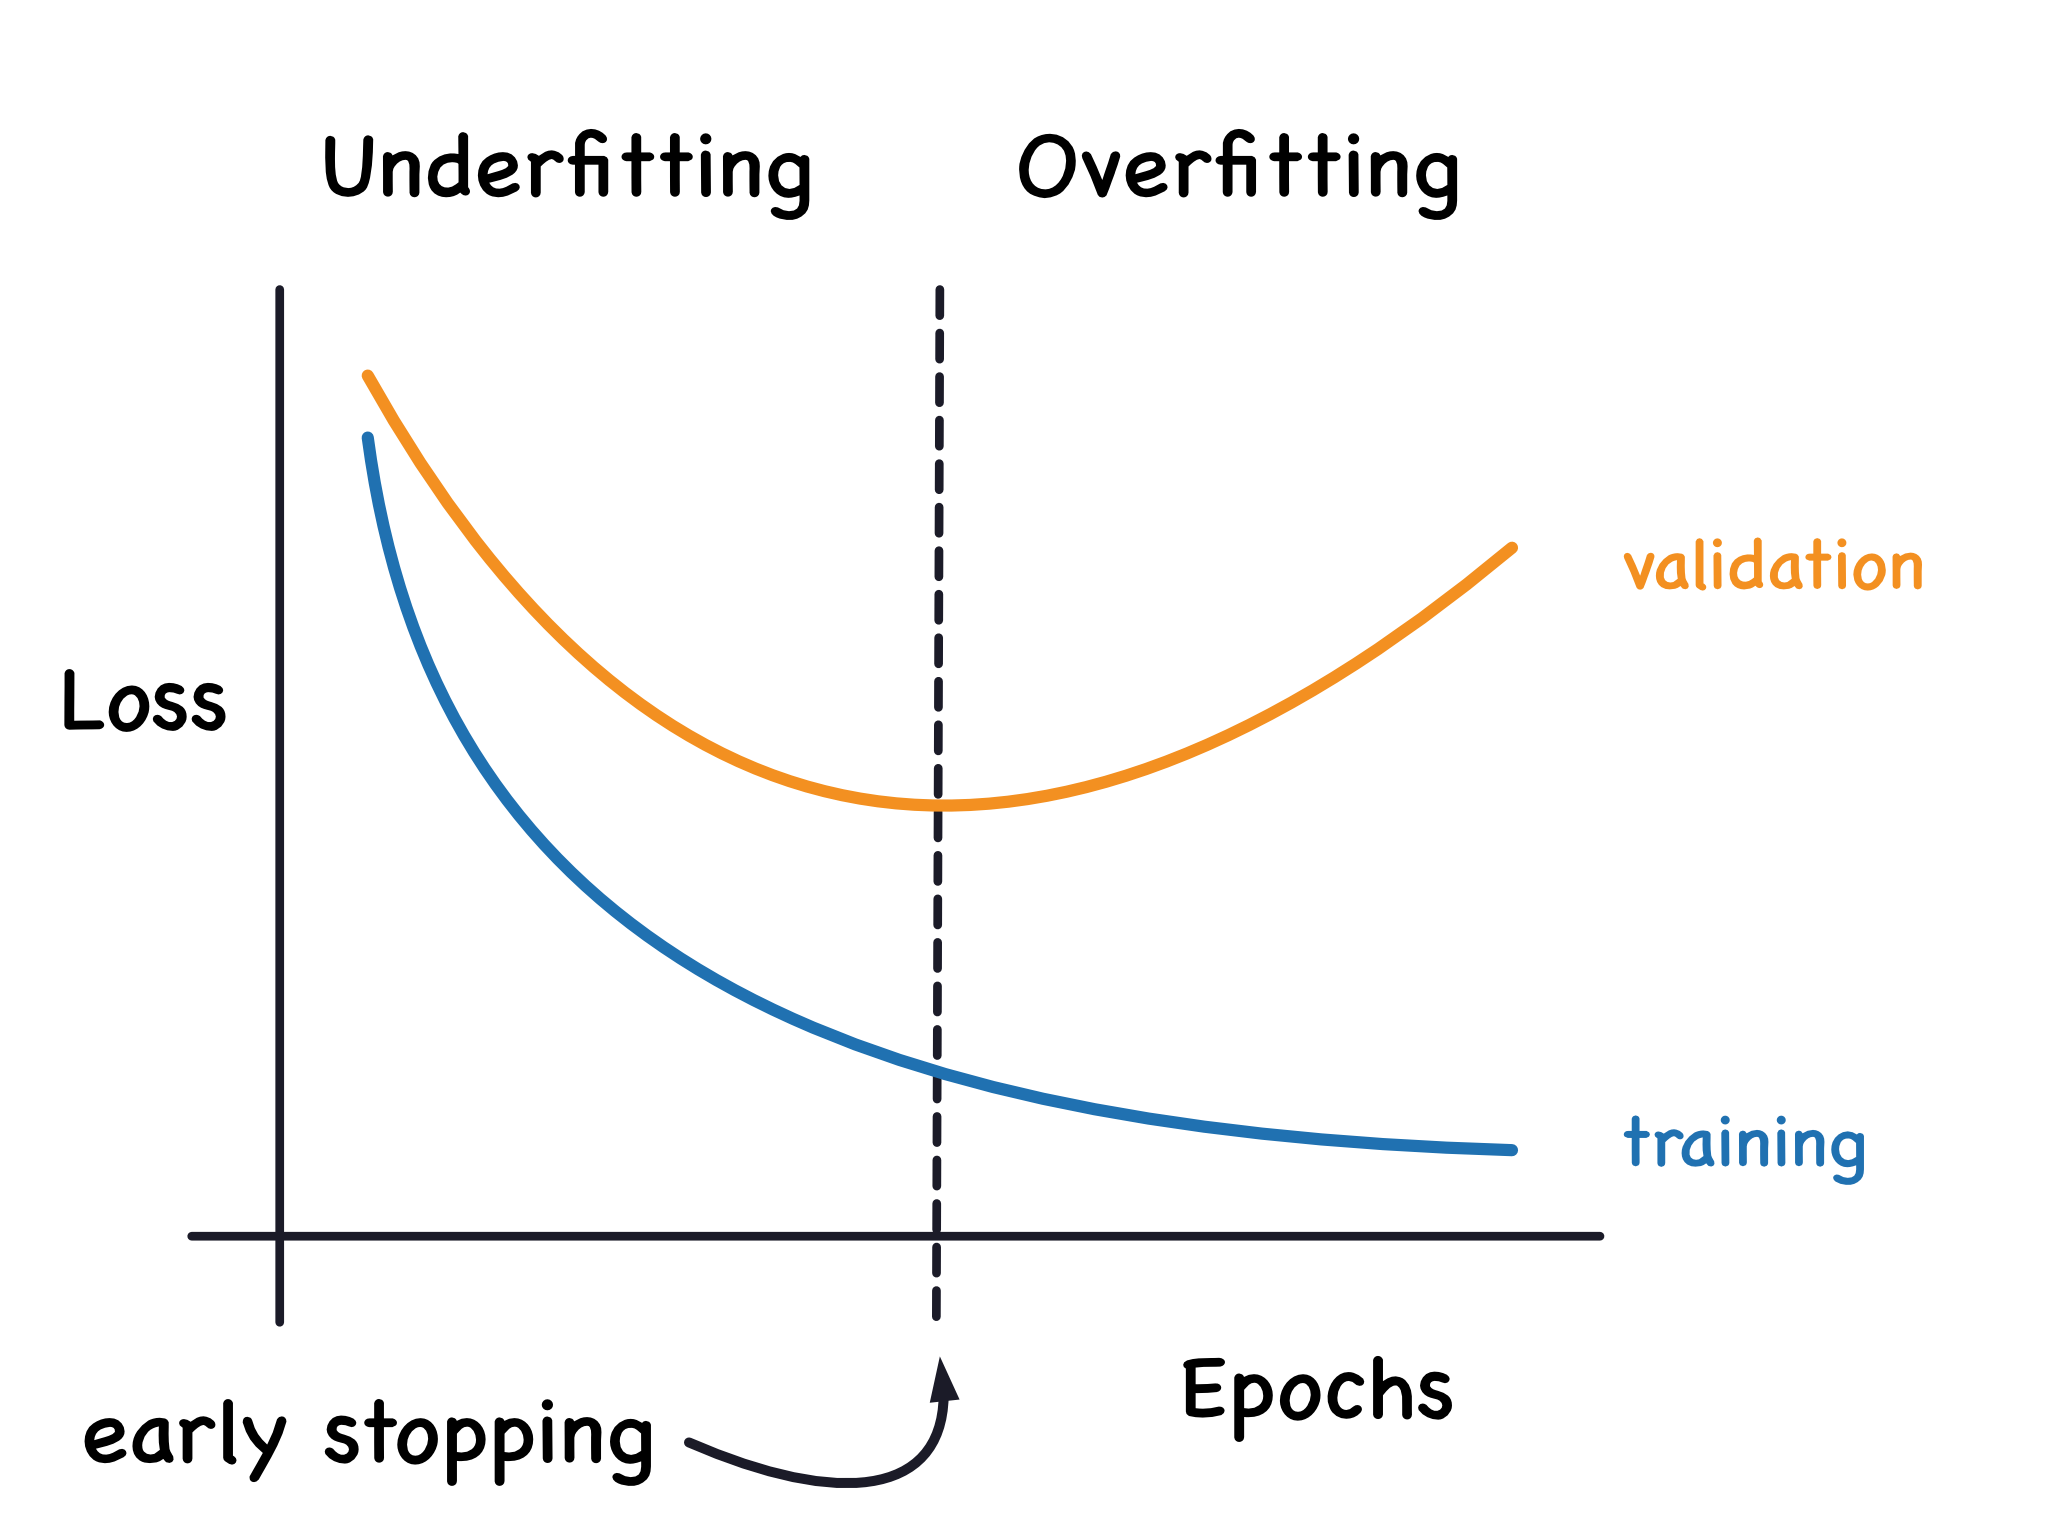
Once we detect that the validation loss is starting to rise again, we can reset the weights back to where the minimum occured. This ensures that the model won't continue to learn noise and overfit the data.

Training with early stopping also means we're in less danger of stopping the training too early, before the network has finished learning signal. So besides preventing overfitting from training too long, early stopping can also prevent underfitting from not training long enough. Just set your training epochs to some large number (more than you'll need), and early stopping will take care of the rest.

## Adding Early Stopping
In Keras, we include early stopping in our training through a `callback`. A callback is just a function we want run every so often while the network trains. `The early stopping callback will run after every epoch`.

In [1]:
from tensorflow import keras
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import EarlyStopping

early_stopping=EarlyStopping(
    min_delta=0.001,
    patience=20,
    restore_best_weights=True
)

These parameters say: "If there hasn't been at least an improvement of `0.001` in the validation loss over the previous `20` epochs, then stop the training and keep the best model you found." It can sometimes be hard to tell if the validation loss is rising due to overfitting or just due to random batch variation. The parameters allow us to set some allowances around when to stop.

As we'll see in our example, we'll pass this callback to the fit method along with the loss and optimizer.

In [2]:
# Training a Model with Early Stopping
import pandas as pd
import numpy as np
import joblib

X_train=pd.read_csv('train_data.csv')
X_valid=pd.read_csv('validation_data.csv')

y_train=np.load('y_train.npy')
y_valid=np.load('y_valid.npy')

model=joblib.load('model.pkl')

In [3]:
model.compile(
    loss='mae',
    optimizer='adam'
)

history=model.fit(
    X_train,y_train,
    validation_data=(X_valid,y_valid),
    batch_size=256,
    epochs=500,
    callbacks=[early_stopping],
    verbose=0
)

<Axes: >

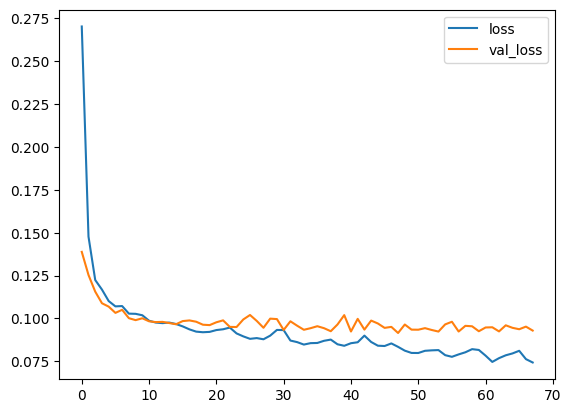

In [4]:
history_df=pd.DataFrame(history.history)
history_df[['loss','val_loss']].plot()

In [5]:
print("Minimum validation loss: {}".format(history_df['val_loss'].min()))

Minimum validation loss: 0.09153364598751068
